2025-08-02 08:31:22.436291: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1754123482.702765      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1754123482.780583      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


Found 13104 images belonging to 15 classes.
Found 300 images belonging to 15 classes.
Found 750 images belonging to 15 classes.


I0000 00:00:1754123502.557627      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 253, 253, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 126, 126, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 124, 124, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 246016)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │    15,745,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 15)             │           975 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

...

Epoch 1/100


I0000 00:00:1754123510.011049      81 service.cc:148] XLA service 0x7c1cc0005240 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1754123510.012253      81 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1754123510.299732      81 cuda_dnn.cc:529] Loaded cuDNN version 90300


  1/410 ━━━━━━━━━━━━━━━━━━━━ 50:35 7s/step - accuracy: 0.1250 - loss: 2.7093

I0000 00:00:1754123514.290693      81 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


410/410 ━━━━━━━━━━━━━━━━━━━━ 474s 1s/step - accuracy: 0.2438 - loss: 2.8318 - val_accuracy: 0.3033 - val_loss: 2.3674
Epoch 2/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 336s 820ms/step - accuracy: 0.4600 - loss: 1.7319 - val_accuracy: 0.3400 - val_loss: 2.4218
Epoch 3/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 332s 808ms/step - accuracy: 0.5377 - loss: 1.4961 - val_accuracy: 0.4067 - val_loss: 2.2797
Epoch 4/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 333s 813ms/step - accuracy: 0.5675 - loss: 1.3875 - val_accuracy: 0.4133 - val_loss: 2.1761
Epoch 5/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 349s 851ms/step - accuracy: 0.6139 - loss: 1.2417 - val_accuracy: 0.4400 - val_loss: 1.9912
Epoch 6/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 344s 839ms/step - accuracy: 0.6309 - loss: 1.1601 - val_accuracy: 0.4667 - val_loss: 2.1787
Epoch 7/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 332s 808ms/step - accuracy: 0.6744 - loss: 1.0316 - val_accuracy: 0.4967 - val_loss: 1.9398
Epoch 8/100
410/410 ━━━━━━━━━━━━━━━━━━━━ 333s 813ms/step - accuracy: 0.6766 - loss: 

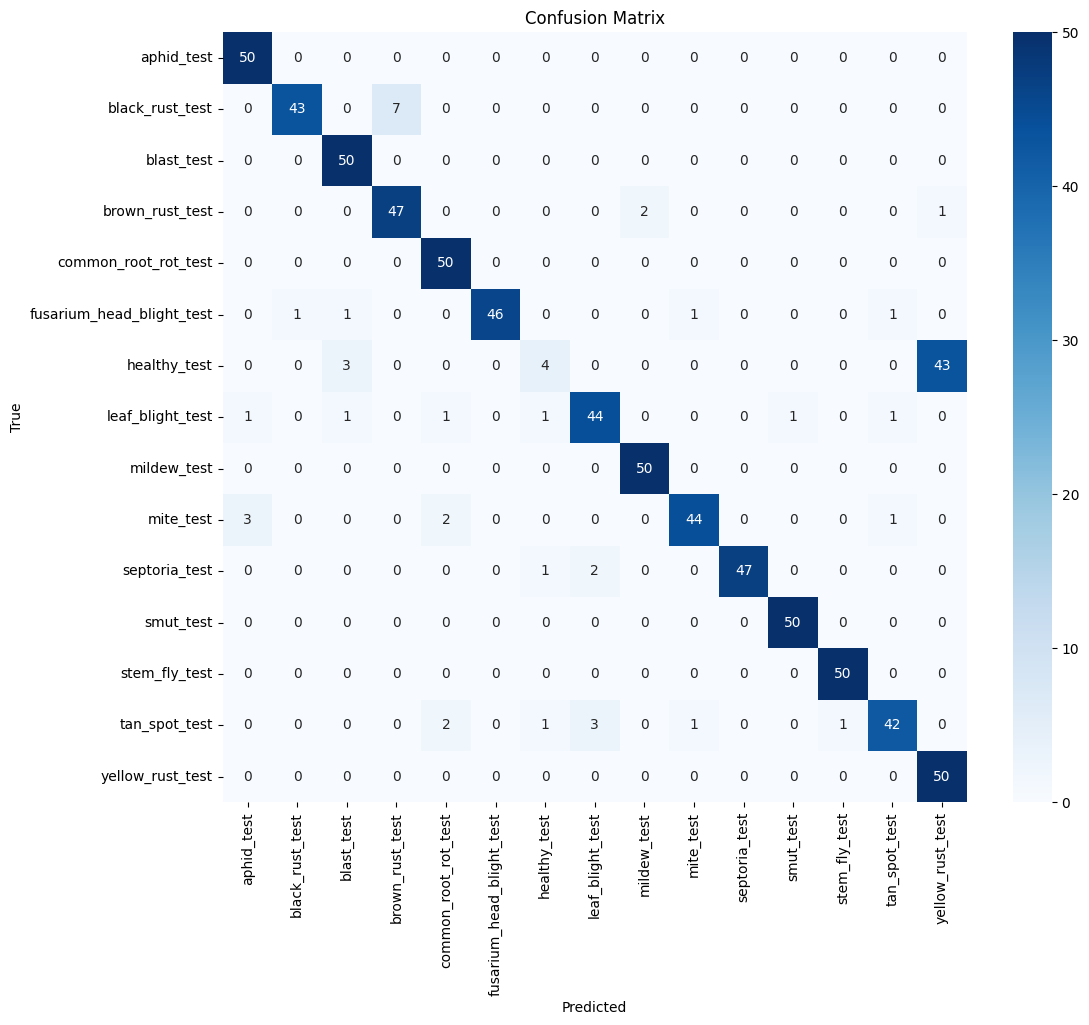

Confusion matrix saved at /kaggle/working/output/confusion_matrix.png


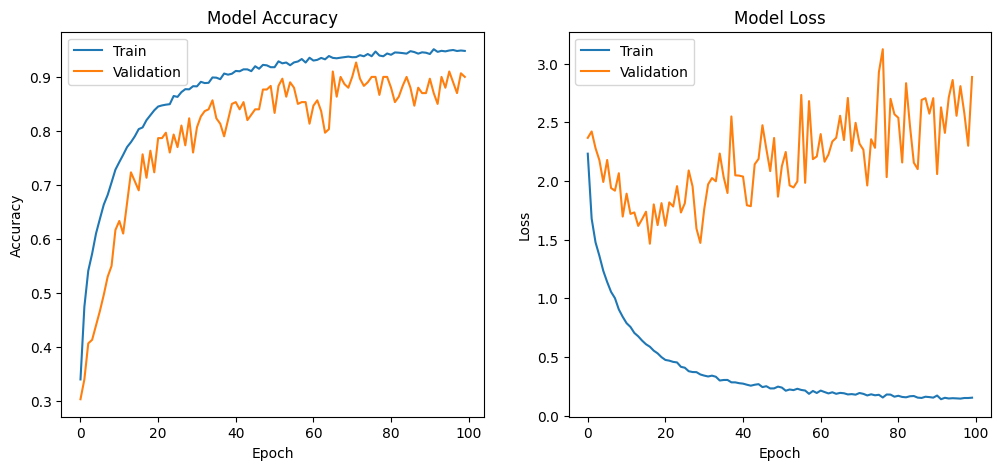

Training history plot saved at /kaggle/working/output/training_history.png


In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
import keras

from keras.src.legacy.preprocessing.image import ImageDataGenerator
from keras.src import applications
from keras.models import Sequential, load_model
from keras.src.layers import Conv2D, MaxPooling2D, GlobalAveragePooling2D, Flatten, Dense, Dropout
from keras.src.legacy.preprocessing import image

import cv2
import os

import warnings
warnings.filterwarnings('ignore')

# Data Augmentation on train dataset
train_datagen = ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

# Data Augmentation on test dataset
test_datagen = ImageDataGenerator(
    rescale=1./255
)

train_generator = train_datagen.flow_from_directory(
    '/kaggle/input/wheat-plant-diseases/data/train',
    target_size=(255,255),
    batch_size=32,
    class_mode='categorical'
)

valid_generator = test_datagen.flow_from_directory(
    '/kaggle/input/wheat-plant-diseases/data/valid',
    target_size=(255,255),
    batch_size=32,
    class_mode='categorical'
)

# Load test data for final evaluation
test_generator = test_datagen.flow_from_directory(
    '/kaggle/input/wheat-plant-diseases/data/test',  # Make sure this path is correct
    target_size=(255,255),
    batch_size=32,
    class_mode='categorical',
    shuffle=False  # Important for correct label ordering
)

model = Sequential()
model.add(Conv2D(32,(3,3),input_shape=(255,255,3),activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D(pool_size=(2,2)))
model.add(Flatten())
model.add(Dense(64,activation='relu'))
model.add(Dense(15,activation='softmax'))

model.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])
model.summary()

history = model.fit(
        train_generator,
        batch_size=32,
        epochs=100,
        validation_data=valid_generator,
        validation_batch_size=32,
)

# Create output directory if it doesn't exist
os.makedirs('/kaggle/working/output', exist_ok=True)

# Save model in Kaggle's output directory
model.save('/kaggle/working/output/WheatDiseaseDetection.h5')
print("Model saved successfully at /kaggle/working/output/WheatDiseaseDetection.h5")

# Generate predictions for the test set
test_pred = model.predict(test_generator)
test_pred_classes = np.argmax(test_pred, axis=1)

# Get true labels
test_true_classes = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# Print classification report
print("\nClassification Report:")
print(classification_report(test_true_classes, test_pred_classes, target_names=class_labels))

# Plot confusion matrix
cm = confusion_matrix(test_true_classes, test_pred_classes)
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.savefig('/kaggle/working/output/confusion_matrix.png')
plt.show()
print("Confusion matrix saved at /kaggle/working/output/confusion_matrix.png")

# Plot training history
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Validation'], loc='upper left')

plt.savefig('/kaggle/working/output/training_history.png')
plt.show()
print("Training history plot saved at /kaggle/working/output/training_history.png")

In [2]:
# import os
# import numpy as np
# import tensorflow as tf
# from tensorflow.keras.preprocessing.image import ImageDataGenerator
# from tensorflow.keras.applications import EfficientNetB4
# from tensorflow.keras.models import Model
# from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout, BatchNormalization
# from tensorflow.keras.optimizers import Adam
# from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
# from tensorflow.keras.regularizers import l2
# from sklearn.metrics import classification_report
# import matplotlib.pyplot as plt

# # Set random seeds for reproducibility
# tf.random.set_seed(42)
# np.random.seed(42)

# # Dataset paths
# train_dir = '/kaggle/input/wheat-plant-diseases/data/train'
# valid_dir = '/kaggle/input/wheat-plant-diseases/data/valid'
# test_dir = '/kaggle/input/wheat-plant-diseases/data/test'

# # Optimized parameters
# IMG_SIZE = (380, 380)  # EfficientNetB4 optimal size
# BATCH_SIZE = 32
# EPOCHS = 50
# INITIAL_LR = 0.001

# # Enhanced data augmentation
# train_datagen = ImageDataGenerator(
#     rescale=1./255,
#     rotation_range=45,
#     width_shift_range=0.2,
#     height_shift_range=0.2,
#     shear_range=0.2,
#     zoom_range=0.2,
#     horizontal_flip=True,
#     vertical_flip=True,
#     brightness_range=[0.8, 1.2],
#     fill_mode='reflect'
# )

# # Validation and test generators
# valid_test_datagen = ImageDataGenerator(rescale=1./255)

# # Data generators
# train_generator = train_datagen.flow_from_directory(
#     train_dir,
#     target_size=IMG_SIZE,
#     batch_size=BATCH_SIZE,
#     class_mode='categorical',
#     shuffle=True
# )

# valid_generator = valid_test_datagen.flow_from_directory(
#     valid_dir,
#     target_size=IMG_SIZE,
#     batch_size=BATCH_SIZE,
#     class_mode='categorical',
#     shuffle=False
# )

# test_generator = valid_test_datagen.flow_from_directory(
#     test_dir,
#     target_size=IMG_SIZE,
#     batch_size=BATCH_SIZE,
#     class_mode='categorical',
#     shuffle=False
# )

# # Class information
# class_names = list(train_generator.class_indices.keys())
# NUM_CLASSES = len(class_names)

# # Load pre-trained EfficientNetB4
# base_model = EfficientNetB4(
#     weights='imagenet',
#     include_top=False,
#     input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3)
# )

# # Freeze base model initially
# base_model.trainable = False

# # Enhanced model architecture
# inputs = tf.keras.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3))
# x = base_model(inputs, training=False)
# x = GlobalAveragePooling2D()(x)
# x = BatchNormalization()(x)
# x = Dense(1024, activation='relu', kernel_regularizer=l2(0.01))(x)
# x = Dropout(0.5)(x)
# x = BatchNormalization()(x)
# outputs = Dense(NUM_CLASSES, activation='softmax')(x)

# model = Model(inputs, outputs)

# # Custom learning rate schedule
# def lr_schedule(epoch):
#     if epoch < 10:
#         return INITIAL_LR
#     elif epoch < 25:
#         return INITIAL_LR * 0.1
#     else:
#         return INITIAL_LR * 0.01

# # Optimizer
# optimizer = Adam(learning_rate=INITIAL_LR)

# model.compile(
#     optimizer=optimizer,
#     loss='categorical_crossentropy',
#     metrics=['accuracy']
# )

# # Enhanced callbacks
# callbacks = [
#     EarlyStopping(monitor='val_accuracy', patience=10, restore_best_weights=True, mode='max'),
#     ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6),
#     ModelCheckpoint('best_model.h5', monitor='val_accuracy', save_best_only=True, mode='max'),
#     tf.keras.callbacks.LearningRateScheduler(lr_schedule)
# ]

# # Phase 1: Train the classifier head
# print("\n=== Phase 1: Training Classifier Head ===")
# history = model.fit(
#     train_generator,
#     steps_per_epoch=len(train_generator),
#     epochs=20,
#     validation_data=valid_generator,
#     validation_steps=len(valid_generator),
#     callbacks=callbacks
# )

# # Phase 2: Fine-tune the model
# print("\n=== Phase 2: Fine-Tuning ===")
# base_model.trainable = True
# # Unfreeze top layers gradually
# for layer in base_model.layers[:100]:
#     layer.trainable = False

# # Recompile with lower learning rate
# model.compile(
#     optimizer=Adam(learning_rate=INITIAL_LR/10),
#     loss='categorical_crossentropy',
#     metrics=['accuracy']
# )

# # Continue training
# history_fine = model.fit(
#     train_generator,
#     steps_per_epoch=len(train_generator),
#     epochs=EPOCHS,
#     initial_epoch=history.epoch[-1],
#     validation_data=valid_generator,
#     validation_steps=len(valid_generator),
#     callbacks=callbacks
# )

# # Evaluation
# def evaluate_model(generator, name):
#     y_true = generator.classes
#     y_pred = model.predict(generator)
#     y_pred_classes = np.argmax(y_pred, axis=1)
    
#     print(f"\n{name} Classification Report:")
#     print(classification_report(y_true, y_pred_classes, target_names=class_names))
    
#     accuracy = np.mean(y_true == y_pred_classes)
#     print(f"{name} Accuracy: {accuracy:.4f}")
#     return accuracy

# # Evaluate on all sets
# val_accuracy = evaluate_model(valid_generator, "Validation")
# test_accuracy = evaluate_model(test_generator, "Test")

# # Plot training history
# plt.figure(figsize=(15, 5))
# plt.subplot(1, 2, 1)
# plt.plot(history.history['accuracy'] + history_fine.history['accuracy'], label='Train')
# plt.plot(history.history['val_accuracy'] + history_fine.history['val_accuracy'], label='Validation')
# plt.title('Model Accuracy')
# plt.ylabel('Accuracy')
# plt.xlabel('Epoch')
# plt.legend()

# plt.subplot(1, 2, 2)
# plt.plot(history.history['loss'] + history_fine.history['loss'], label='Train')
# plt.plot(history.history['val_loss'] + history_fine.history['val_loss'], label='Validation')
# plt.title('Model Loss')
# plt.ylabel('Loss')
# plt.xlabel('Epoch')
# plt.legend()
# plt.show()

# # Save the final model
# model.save('high_accuracy_wheat_model.h5')
# print("\nModel saved successfully!")